<a href="https://colab.research.google.com/github/NilsChabloz/2026_Intro_Python/blob/main/live/part-I/1.5-pandas-environmental-exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> Notebook-friendly copy of `part-I/1.5-pandas-environmental-exercises.ipynb`, generated by `tools/make_live.py`. Edit the book notebook, not this file.

In [1]:
# --- environment setup (generated, not part of the lesson) ---
# Colab and Kaggle do not ship every package this notebook imports.
# This is a no-op in an environment that is already set up.
import importlib.util
import subprocess
import sys

for module, package in {"pooch": "pooch"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

# Environmental Exercises

**ℹ️ How to use these exercises**

Attempt each from scratch in the empty code cell. Import pandas as `pd` and numpy as `np`, seed any randomness with `default_rng`, and keep units in your column names.

## Exercise 1: Earthquake data analysis

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/usgs-2014-south-napa-earthquake.jpg" alt="A dirt track through a vineyard, broken along its length by a continuous ridge of pushed-up soil following the fault trace" width="800">

<em>Surface rupture from the magnitude 6.0 South Napa earthquake of 24 August 2014 — the kind of event a row in this catalog stands for. The continuous "mole track" running parallel to the strike of the fault indicates some east–west compression on top of the <a href="https://www.usgs.gov/faqs/what-fault-and-what-are-different-types">right-lateral faulting</a>; taken near Buhman Road. Photo <a href="https://www.usgs.gov/media/images/2014-south-napa-ca-m6-earthquake-august-24-6">USGS</a>, public domain.</em>


This exercise reviews the `pandas` fundamentals of this subchapter on one real catalog, covering how to

* open csv files
* manipulate dataframe indexes
* parse date columns
* examine basic dataframe statistics
* manipulate text columns and extract values
* plot dataframe contents using
  * bar charts
  * histograms
  * scatter plots

The data is a snapshot of the [USGS Earthquakes Database](https://earthquake.usgs.gov/earthquakes/search/): every event recorded worldwide in 2014, 120 108 rows.

You do not need to download the file yourself. The pre-supplied cell below fetches and caches it with the help of [pooch](https://www.fatiando.org/pooch/latest/) — there is no need to read pooch's documentation unless you want to — and stores the path to the file in the variable `datafile`.

In [2]:
# Pre-supplied: download and cache the earthquake data.
import pooch

datafile = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/usgs_earthquakes_2014.csv",
    known_hash="sha256:84d455fb96dc8f782fba4b5fbe56cb8970cab678f07c766fcba1b1c4674de1b1",
    fname="usgs_earthquakes_2014.csv",
    path=pooch.os_cache("mlees"),
)

**ℹ️ Beyond this subchapter**

The tools below were not demonstrated in 1.5's lecture. Each question links its documentation where
it is needed; they are collected here so you know when you are being asked to read a new page rather
than to recall one:

- [`nlargest`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.nlargest.html) — Q5
- [pandas' text data functions](https://pandas.pydata.org/pandas-docs/stable/user_guide/text.html), and [`Series.str.split`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.str.split.html) in particular — Q6
- [`unique`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.unique.html) — Q7
- [`count`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.count.html) and [`value_counts`](https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html) — Q9

The scatter plot and colorbar in Q11 are the ones from 1.4.6. Everything else the questions ask for
is from this subchapter's lecture: `read_csv` with date-parsed columns, `set_index`, `.head()`,
`.info()`, `.describe()`, boolean filtering, `.index` and `.values`, `kind="bar"`, `kind="hist"`, and
a logarithmic count axis.

**Q1) First, import `numpy`, `pandas` and `matplotlib`, and — optionally — set the display options.**

Hint: display options are documented [at this link](https://pandas.pydata.org/pandas-docs/stable/user_guide/options.html).

In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

**Q2) Use pandas' `read_csv` function directly on `datafile` to open it as a `DataFrame`.**

Display the first few rows with `.head()`, and the column names, dtypes and non-null counts with
`.info()`. Check these tutorials if you have doubts about what the two functions do:
[`.head()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.head.html)
and
[`.info()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.info.html?highlight=info#pandas.DataFrame.info).

`.info()` will show you that the two date columns, `time` and `updated`, came in as plain strings
rather than as dates. They were not parsed automatically. What can you do about that?

In [11]:
# Open the file as a pandas DataFrame, then display the first few rows and the DataFrame info
earthquakes = pd.read_csv(datafile)
earthquakes.head()
#earthquakes.info()

,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,net,id,updated,place,type
0,2014-01-31 23:53:37.000,60.252000,-152.7081,90.20,1.10,ml,NaN,NaN,NaN,0.2900,ak,ak11155107,2014-02-05T19:34:41.515Z,"26km S of Redoubt Volcano, Alaska",earthquake
1,2014-01-31 23:48:35.452,37.070300,-115.1309,0.00,1.33,ml,4.0,171.43,0.34200,0.0247,nn,nn00436847,2014-02-01T01:35:09.000Z,"32km S of Alamo, Nevada",earthquake
2,2014-01-31 23:47:24.000,64.671700,-149.2528,7.10,1.30,ml,NaN,NaN,NaN,1.0000,ak,ak11151142,2014-02-01T00:03:53.010Z,"12km NNW of North Nenana, Alaska",earthquake
3,2014-01-31 23:30:54.000,63.188700,-148.9575,96.50,0.80,ml,NaN,NaN,NaN,1.0700,ak,ak11151135,2014-01-31T23:41:25.007Z,"22km S of Cantwell, Alaska",earthquake
4,2014-01-31 23:30:52.210,32.616833,-115.6925,10.59,1.34,ml,6.0,285.00,0.04321,0.2000,ci,ci37171541,2014-02-01T00:13:20.107Z,"10km WNW of Progreso, Mexico",earthquake


**Q3) Re-read the data in such a way that both date columns are identified as dates and the earthquake ID is used as the index.**

Check with `.head()` and `.info()` that it worked: `time` and `updated` should now be
`datetime64` columns, and `id` should be the index rather than a column.

Hint: the documentation for `read_csv` is [here](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.read_csv.html?highlight=read_csv).

In [20]:
earthquakes = pd.read_csv(datafile, parse_dates=['time', 'updated'])
earthquakes = earthquakes.set_index('id')
earthquakes.head()
#earthquakes.info()

,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,net,updated,place,type
id,,,,,,,,,,,,,,
ak11155107,2014-01-31 23:53:37.000,60.252000,-152.7081,90.20,1.10,ml,NaN,NaN,NaN,0.2900,ak,2014-02-05 19:34:41.515000+00:00,"26km S of Redoubt Volcano, Alaska",earthquake
nn00436847,2014-01-31 23:48:35.452,37.070300,-115.1309,0.00,1.33,ml,4.0,171.43,0.34200,0.0247,nn,2014-02-01 01:35:09+00:00,"32km S of Alamo, Nevada",earthquake
ak11151142,2014-01-31 23:47:24.000,64.671700,-149.2528,7.10,1.30,ml,NaN,NaN,NaN,1.0000,ak,2014-02-01 00:03:53.010000+00:00,"12km NNW of North Nenana, Alaska",earthquake
ak11151135,2014-01-31 23:30:54.000,63.188700,-148.9575,96.50,0.80,ml,NaN,NaN,NaN,1.0700,ak,2014-01-31 23:41:25.007000+00:00,"22km S of Cantwell, Alaska",earthquake
ci37171541,2014-01-31 23:30:52.210,32.616833,-115.6925,10.59,1.34,ml,6.0,285.00,0.04321,0.2000,ci,2014-02-01 00:13:20.107000+00:00,"10km WNW of Progreso, Mexico",earthquake


**Q4) Use `describe` to get the basic statistics of all the columns.**

Hint: the documentation of `describe` is [at this link](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html).

In [102]:
earthquakes.describe()

,time,latitude,longitude,depth,mag,nst,gap,dmin,rms
count,120108,120108.000000,120108.000000,120107.000000,120065.000000,59688.000000,94935.000000,85682.000000,119716.000000
mean,2014-07-05 09:10:37.116720128,38.399579,-99.961402,28.375029,1.793958,17.878284,124.048978,0.893198,0.358174
min,2014-01-01 00:01:16.610000,-73.462000,-179.998900,-9.900000,-0.970000,0.000000,9.000000,0.000000,0.000000
25%,2014-04-08 03:43:10.768999936,34.228917,-147.742025,4.100000,0.820000,8.000000,74.000000,0.020760,0.070000
50%,2014-07-07 10:44:06.035000064,38.805300,-120.832000,9.200000,1.400000,14.000000,107.000000,0.073670,0.200000
75%,2014-09-30 23:36:40.595000064,53.889500,-116.068100,22.880000,2.400000,22.000000,155.000000,0.447000,0.590000
max,2014-12-31 23:54:33.900000,86.651400,179.998000,697.360000,8.200000,365.000000,356.400000,64.498000,8.460000
std,NaN,21.938258,82.996858,62.215416,1.343466,14.911369,68.518595,2.903966,0.364046


**Q5) Use `nlargest` to get the top 20 earthquakes by magnitude.**

Hint: the documentation of `nlargest` is [at this link](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.nlargest.html).

In [19]:
# Use nlargest
largest_mag = earthquakes.nlargest(20, earthquakes.loc('mag'))

ValueError: No axis named mag for object type DataFrame

In [23]:
largest_mag = earthquakes.nlargest(20, earthquakes.loc['mag'])

KeyError: 'mag'

⚛ *Reflective assignement notes*
---
> **What I got wrong here:**
> I misunderstood what argument `nlargest` take. It takes the column label directly, so I don't need to select the whole column by hand.





In [27]:
largest_mag = earthquakes.nlargest(20, 'mag')

**Q6) Extract the state or country using pandas' text data functions, and add it as a new column to the `DataFrame`.**

Examine the column titled `place`: it holds strings like `"26km S of Redoubt Volcano, Alaska"`, so
it carries both the local description and the state or country. Pull the second part out and store
it in a new column called `country`.

Hint 1: the documentation for pandas' text data functions is [here](https://pandas.pydata.org/pandas-docs/stable/text.html).

Hint 2: you will use `.split()` to extract the country names. The documentation of this function
can be found [here](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.str.split.html?highlight=split#pandas.Series.str.split).

In [33]:
# Extract the state or country, and add it as a new column to the DataFrame called country
earthquakes['country'] = earthquakes['place'].split(',')

AttributeError: 'Series' object has no attribute 'split'

In [38]:
earthquakes['country'] = earthquakes['place'].str.split(',')[-1]
earthquakes.head()

/tmp/ipykernel_1097/856836829.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  earthquakes['country'] = earthquakes['place'].str.split(',')[-1]


ValueError: Length of values (2) does not match length of index (120108)

In [41]:
earthquakes['country'] = earthquakes['place'].str.split(',').str[-1]
earthquakes.head()

,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,net,updated,place,type,country
id,,,,,,,,,,,,,,,
ak11155107,2014-01-31 23:53:37.000,60.252000,-152.7081,90.20,1.10,ml,NaN,NaN,NaN,0.2900,ak,2014-02-05 19:34:41.515000+00:00,"26km S of Redoubt Volcano, Alaska",earthquake,Alaska
nn00436847,2014-01-31 23:48:35.452,37.070300,-115.1309,0.00,1.33,ml,4.0,171.43,0.34200,0.0247,nn,2014-02-01 01:35:09+00:00,"32km S of Alamo, Nevada",earthquake,Nevada
ak11151142,2014-01-31 23:47:24.000,64.671700,-149.2528,7.10,1.30,ml,NaN,NaN,NaN,1.0000,ak,2014-02-01 00:03:53.010000+00:00,"12km NNW of North Nenana, Alaska",earthquake,Alaska
ak11151135,2014-01-31 23:30:54.000,63.188700,-148.9575,96.50,0.80,ml,NaN,NaN,NaN,1.0700,ak,2014-01-31 23:41:25.007000+00:00,"22km S of Cantwell, Alaska",earthquake,Alaska
ci37171541,2014-01-31 23:30:52.210,32.616833,-115.6925,10.59,1.34,ml,6.0,285.00,0.04321,0.2000,ci,2014-02-01 00:13:20.107000+00:00,"10km WNW of Progreso, Mexico",earthquake,Mexico


⚛ *Reflective assignement notes*
---
> **What I got wrong here:**
> I tried to split a series in the beggining, but we want to split each string one by one, so here the `.str()` comes into use. It is kind of the same error with the slicing. Using `earthquakes['place'].str.split(',')[-1]` select the last element of the whole series.

**Q7) Display each unique value from the new `country` column.**

Hint: you may use the `unique` function documented [at this link](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.unique.html).

You should see an array of a couple of hundred country and state names. A plain split leaves the
space that followed the comma, so they come out as `array([' Alaska', ' Nevada', ...])` — worth
removing before you use them as labels.

In [47]:
# Display unique values
countries = earthquakes['country'].unique()
print(countries)

[' Alaska' ' Nevada' ' Mexico' ' California' ' Papua New Guinea'
 ' New Zealand' ' Missouri' 'South of the Fiji Islands' ' Montana'
 ' British Virgin Islands' ' Washington' ' Oregon' ' Canada' ' Fiji'
 'Wyoming' ' Antarctica' ' Chile' ' Utah' ' Indonesia' ' Solomon Islands'
 ' Micronesia' ' Oklahoma' ' Hawaii' ' Wyoming' ' Russia' ' Arizona'
 ' Philippines' ' Bolivia' ' Greece' ' Japan' ' Puerto Rico' ' Iran'
 ' Tonga' ' Wallis and Futuna' ' Colorado' ' Guam' ' CA' 'Carlsberg Ridge'
 ' Idaho' ' Pakistan' 'Off the west coast of northern Sumatra' ' Burma'
 ' China' ' Peru' 'Off the east coast of the North Island of New Zealand'
 ' Costa Rica' 'Reykjanes Ridge' ' East Timor' 'Central East Pacific Rise'
 'Mid-Indian Ridge' ' Japan region' ' Northern Mariana Islands'
 ' El Salvador' ' Samoa' 'Northern Mid-Atlantic Ridge' ' Taiwan'
 ' Arkansas' ' South Sandwich Islands' ' Colombia' ' Dominican Republic'
 ' Argentina' ' Texas' ' New Hampshire' ' Saint Helena'
 'West of Vancouver Island' ' Tan

In [51]:
earthquakes['country'] = earthquakes['place'].str.split(',').str[-1].str.strip()
countries = earthquakes['country'].unique()
print(countries)

['Alaska' 'Nevada' 'Mexico' 'California' 'Papua New Guinea' 'New Zealand'
 'Missouri' 'South of the Fiji Islands' 'Montana' 'British Virgin Islands'
 'Washington' 'Oregon' 'Canada' 'Fiji' 'Wyoming' 'Antarctica' 'Chile'
 'Utah' 'Indonesia' 'Solomon Islands' 'Micronesia' 'Oklahoma' 'Hawaii'
 'Russia' 'Arizona' 'Philippines' 'Bolivia' 'Greece' 'Japan' 'Puerto Rico'
 'Iran' 'Tonga' 'Wallis and Futuna' 'Colorado' 'Guam' 'CA'
 'Carlsberg Ridge' 'Idaho' 'Pakistan'
 'Off the west coast of northern Sumatra' 'Burma' 'China' 'Peru'
 'Off the east coast of the North Island of New Zealand' 'Costa Rica'
 'Reykjanes Ridge' 'East Timor' 'Central East Pacific Rise'
 'Mid-Indian Ridge' 'Japan region' 'Northern Mariana Islands'
 'El Salvador' 'Samoa' 'Northern Mid-Atlantic Ridge' 'Taiwan' 'Arkansas'
 'South Sandwich Islands' 'Colombia' 'Dominican Republic' 'Argentina'
 'Texas' 'New Hampshire' 'Saint Helena' 'West of Vancouver Island'
 'Tanzania' 'Vanuatu' 'Bosnia and Herzegovina' 'India' 'American Samoa'

⚛ *Reflective assignement notes*
---
> **What I got wrong here:**
> I did not remove the white space at the beginning of the country in the beginning. However there is another thing to note. The split I did gives us the country correctly, however, some places have a more descriptive location than just the country (e.g. 'Off the west coast of northern Sumatra'). If I split at ',' only, it will take the description with it. I do not know how to select only the country here, apart from going value by value.

**Q8) Create a filtered dataset that only has earthquakes larger than magnitude 4.**

Hint: print the table to see the name of the column containing the earthquake magnitude.

Check out this [link](https://www.geeksforgeeks.org/ways-to-filter-pandas-dataframe-by-column-values/)
to find examples of filtering by column values.

In [57]:
# Filter the dataset based on the earthquakes' magnitudes
mag4 = earthquakes[earthquakes['mag'] > 4]

**Q9) Using the filtered dataset (magnitude > 4), count the number of earthquakes whose magnitudes are above 4 [Num 1], and count the number of earthquakes in each country or state [Num 2]. Make a bar chart of Num 2 for the top 5 locations with the most earthquakes.**

Hint 1: to get Num 1, pandas has a `count` function documented
[at this link](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.count.html).

Hint 2: check out the
[`value_counts`](https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html)
function to get Num 2.

Then convert the first five rows of Num 2 into a `DataFrame` with two columns, `country` (text)
and `earthquake_num` (number), and recreate the bar chart below.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.5-target-top5-bar.png" alt="A bar chart of the number of magnitude-above-4 earthquakes in the five countries with the most of them" width="700">

<em>The five locations with the most magnitude-above-4 events in 2014.</em>

16371
Index(['Indonesia', 'Papua New Guinea', 'Japan', 'Chile', 'New Zealand'], dtype='object', name='country')


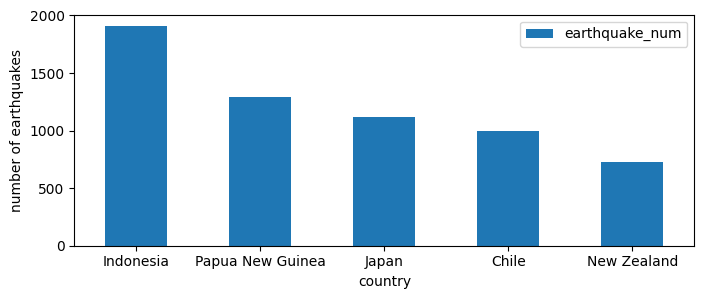

In [82]:
# Count the >4 earthquakes, count them per country, then plot the top 5 as a bar chart
print(mag4['mag'].count())
top5 = mag4['country'].value_counts().head()
print(top5.index)

top5_df = pd.DataFrame({'country' : top5.index, 'earthquake_num': top5.values})
fig, ax = plt.subplots(figsize=(8, 3))
top5_df.plot(ax=ax, kind='bar', x = 'country', y = 'earthquake_num', rot = 0)
ax.set_xlabel('country')
ax.set_ylabel('number of earthquakes')

plt.show()


**Q10) Make a histogram for the distribution of the earthquakes' magnitudes.**

Hint: pandas has a histogram function documented
[at this link](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.hist.html) and
matplotlib has one documented
[at this link](https://matplotlib.org/api/_as_gen/matplotlib.pyplot.hist.html).

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.5-target-magnitude-hist.png" alt="A histogram of earthquake magnitude with a dashed grid" width="700">

<em>The distribution of magnitude across the whole catalog.</em>


Then redraw it with a logarithmic scale on the y-axis, which brings the rare large events into
view alongside the many small ones. Hint: here you can find a
[tutorial](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.yscale.html) for how to
change an axis scale.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.5-target-magnitude-hist-log.png" alt="The same histogram of earthquake magnitude with a logarithmic y-axis" width="700">

<em>The same histogram with a logarithmic count axis.</em>


Finally, make one histogram for the filtered dataset and one for the unfiltered dataset, side by
side.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.5-target-hist-filtered-unfiltered.png" alt="Two histograms of earthquake magnitude side by side, one for events above magnitude 4 and one for the whole catalog" width="100%">

<em>The filtered and unfiltered magnitude distributions, drawn on their own count axes.</em>

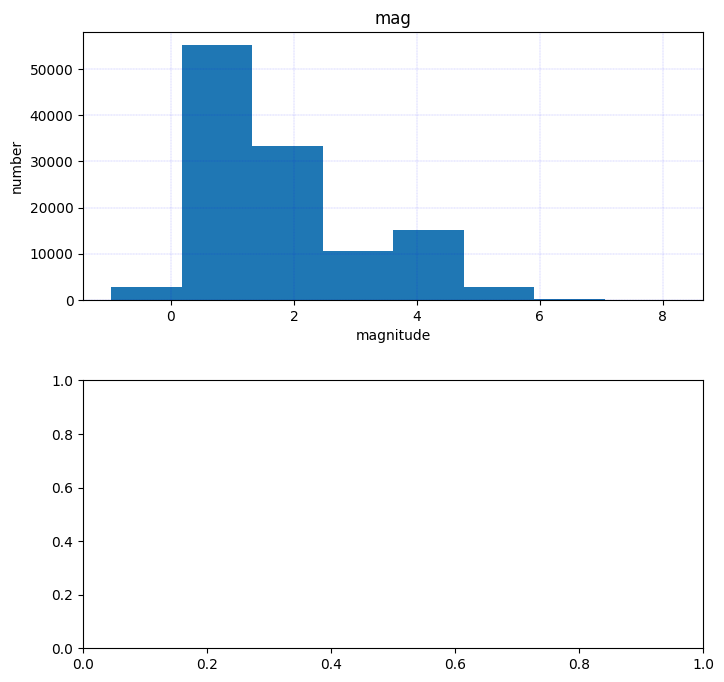

In [106]:
fig, axes = plt.subplots(nrows = 2, ncols = 1, figsize = (8, 8))
ax0, ax1 = axes

earthquakes.hist(column='mag',ax=ax0, bins = 8)
ax0.set_ylabel('number')
ax0.set_xlabel('magnitude')
ax0.grid(which='major', linestyle=':', color='b', linewidth=0.2)

⚛ *Reflective assignement notes*
---
> **What I got wrong here:**
> I did not have the correct bins number, mine was too coarse (`bins=8`). But with `bins=20`, we get something better.

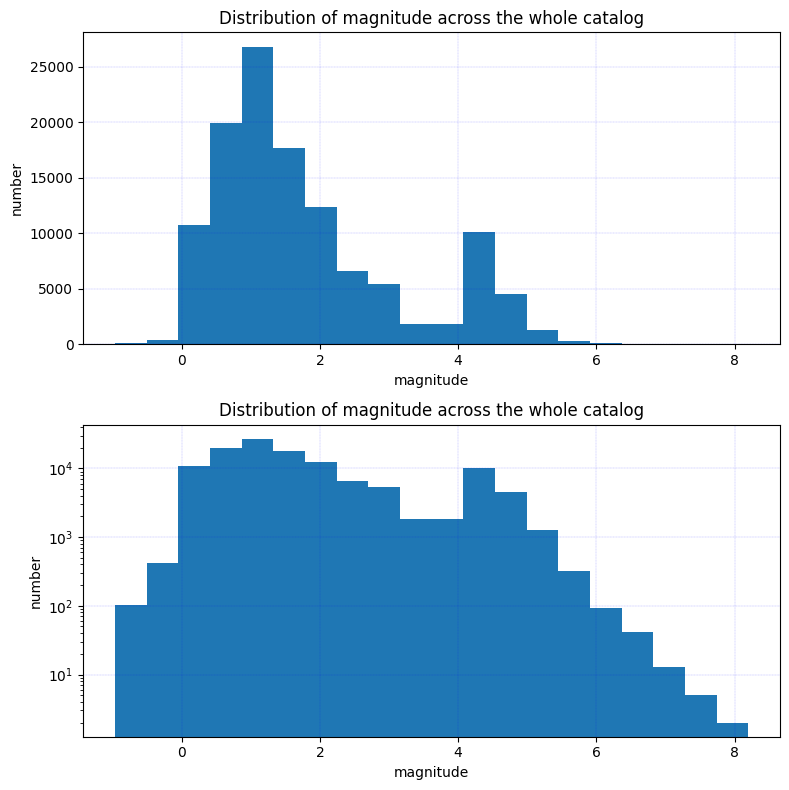

In [114]:
fig, axes = plt.subplots(nrows = 2, ncols = 1, figsize = (8, 8))
ax0, ax1 = axes

earthquakes.hist(column='mag',ax=ax0, bins = 20)

earthquakes.hist(column='mag', ax=ax1, bins=20)
ax1.set_yscale('log')

for axis in axes:
  axis.set_ylabel('number')
  axis.set_xlabel('magnitude')
  axis.grid(which='major', linestyle=':', color='b', linewidth=0.2)
  axis.set_title('Distribution of magnitude across the whole catalog')

plt.tight_layout()
plt.show()

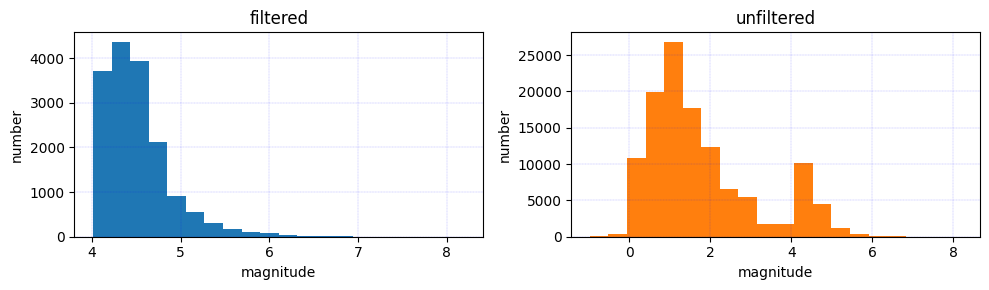

In [121]:
fig, axes = plt.subplots(nrows = 1, ncols = 2, figsize = (10, 3))
ax0, ax1 = axes

mag4.hist(column='mag',ax=ax0, bins = 20)
ax0.set_title('filtered')

earthquakes.hist(column='mag', ax=ax1, bins=20, color = 'tab:orange')
ax1.set_title('unfiltered')

for axis in axes:
  axis.set_ylabel('number')
  axis.set_xlabel('magnitude')
  axis.grid(which='major', linestyle=':', color='b', linewidth=0.2)

plt.tight_layout()
plt.show()

**Q11) Visualise the locations of earthquakes by making a scatterplot of their latitude and longitude.**

Make a figure with two panels: one for the filtered dataset and one for the unfiltered one, with
the points coloured by magnitude on a shared colour range.

Hint: consider reading the documentation for
[`plt.scatter`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html) to make
the scatter plot and that of
[`plt.colorbar`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.colorbar.html) to
colour the points by magnitude. Pass the same `vmin` and `vmax` to both scatter calls, so that a
colour stands for the same magnitude in both panels.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.5-target-quake-scatter.png" alt="Two scatter plots of earthquake longitude against latitude coloured by magnitude, one filtered to magnitude above 4 and one unfiltered" width="100%">

<em>Every event in the catalog placed by longitude and latitude, filtered and unfiltered.</em>

Text(0.5, 1.0, 'unfiltered')

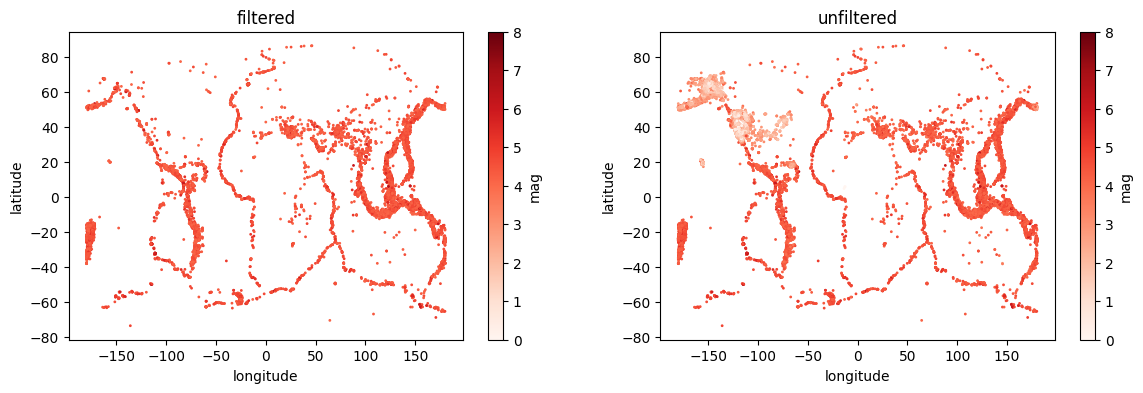

In [136]:
# Make the two scatter plots
fig, axes = plt.subplots(1, 2, figsize=(14,4))
ax0,ax1 = axes
mag4.plot.scatter(ax=ax0, x = 'longitude', y = 'latitude', c = 'mag', s = 1, cmap = 'Reds', vmin = 0, vmax = 8)
ax0.set_title('filtered')

earthquakes.plot.scatter(ax=ax1, x = 'longitude', y = 'latitude', c = 'mag', s = 1, cmap = 'Reds', vmin = 0, vmax = 8)
ax1.set_title('unfiltered')

**Do you notice a difference between the filtered and unfiltered datasets?**

We see that there is an important quantity of low magnitude earthquakes in northern America, that is filtered out in the filtered dataset, this is the main big difference. Otherwise the results are quite similar in the end.